# Tutorial: One labeled training window

Audience:
- Madeleine, Levi, and Pragya, plus tomorrow's status check.

Prerequisites:
- This branch, `joshua/training-pipeline`.
- NumPy and Matplotlib. The functions live in `src/uvnc`.

Learning goals:
- Call `build_labeled_window` on one fake background.
- Read `share_added_vessel` and the dropped minutes.
- See the passage envelope and the fallback ship spectrum.


## Outline

1. Import the entry point.
2. Build one fake 15-by-25 background and label it.
3. Plot the passage envelope.
4. Plot the ship spectrum.
5. Try a different closest-approach minute.


## Setup

The next cell adds `src/` to the path whether you start Jupyter from the repo root or from `notebooks/`. The seed is fixed so the same two minutes drop every run.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
if not (ROOT / "src" / "uvnc").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from uvnc.passage import passage_envelope, ship_spectrum, third_octave_centres
from uvnc.pipeline import build_labeled_window

SEED = 21
N_MINUTES = 15
N_BANDS = 25
CLOSEST_MINUTE = 8
BACKGROUND_DB = 60.0
# 60 dB is 10**6 linear power per cell. This total is one quarter of the
# background energy, so a fully observed window has a share near 0.2.
ADDED_ENERGY = 0.25 * N_MINUTES * N_BANDS * 10 ** (BACKGROUND_DB / 10.0)
N_DROP = 2


## One fake window

Every cell is 60 dB. That is a stand-in background, not a row from `Test.csv`. The passage energy is linear power, sized to about one fifth of the mixture. Training backgrounds will come from the South African site files.

`build_labeled_window` mixes the fallback passage in linear power, blanks whole minutes, and returns the energy-fraction label.


In [2]:
background_db = np.full((N_MINUTES, N_BANDS), BACKGROUND_DB)
mixture_db, share, metadata = build_labeled_window(
    background_db,
    closest_minute=CLOSEST_MINUTE,
    added_energy=ADDED_ENERGY,
    seed=SEED,
    n_drop=N_DROP,
)

print(f"share_added_vessel = {share:.4f}")
print("dropped minutes =", metadata["dropped_minutes"])
print("mixture shape =", mixture_db.shape)


share_added_vessel = 0.2020
dropped minutes = [5, 12]
mixture shape = (15, 25)


## Passage envelope

The curve is the fraction of passage energy in each minute. It peaks at minute 8. Dashed lines mark the minutes this seed dropped. Those minutes are missing in the mixture, and they are left out of both sums in the share.


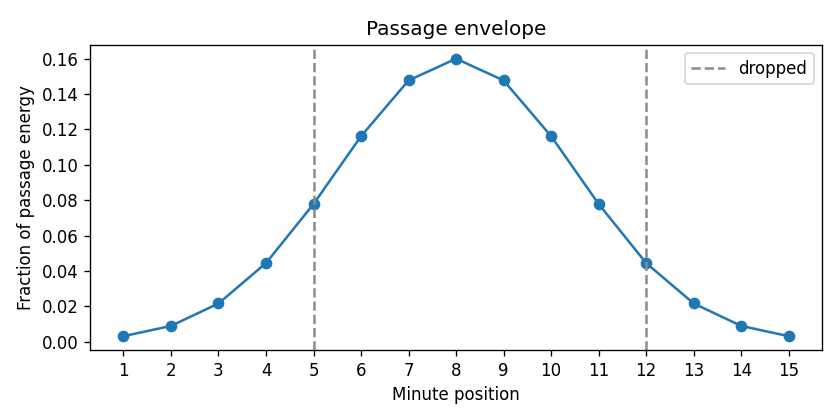

In [3]:
minutes = np.arange(1, N_MINUTES + 1)
envelope = passage_envelope(N_MINUTES, metadata["closest_minute"])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(minutes, envelope, marker="o")
for minute in metadata["dropped_minutes"]:
    ax.axvline(minute, color="0.55", linestyle="--", label="dropped" if minute == metadata["dropped_minutes"][0] else None)
ax.set_xlabel("Minute position")
ax.set_ylabel("Fraction of passage energy")
ax.set_title("Passage envelope")
ax.set_xticks(minutes)
ax.legend()
fig.tight_layout()


## Ship spectrum

This is the `1 / frequency` fallback, not a VTUAD recording. Low bands carry more of the passage energy. The centres match `minute_band_power` in the starter notebook.


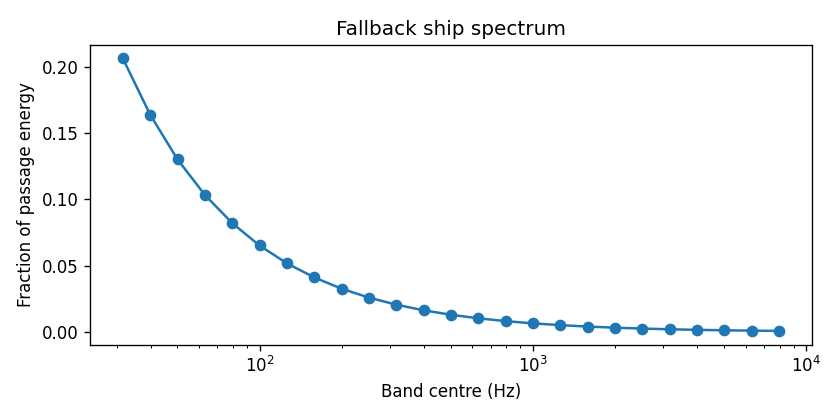

In [4]:
centres = third_octave_centres()
spectrum = ship_spectrum()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(centres, spectrum, marker="o")
ax.set_xscale("log")
ax.set_xlabel("Band centre (Hz)")
ax.set_ylabel("Fraction of passage energy")
ax.set_title("Fallback ship spectrum")
fig.tight_layout()


## Pitfall

Do not add the passage in decibels, and do not use `Test.csv` as a training background. The entry point already converts to linear power and labels only the cells that remain after the minute mask.

## Exercise

Move closest approach from minute 8 to minute 2. The peak of the envelope should move with it, and the share should change because a different part of the passage is dropped.


In [5]:
_, share_early, meta_early = build_labeled_window(
    background_db,
    closest_minute=2,
    added_energy=ADDED_ENERGY,
    seed=SEED,
    n_drop=N_DROP,
)
early_envelope = passage_envelope(N_MINUTES, meta_early["closest_minute"])
print("peak minute =", int(np.argmax(early_envelope) + 1))
print(f"share_added_vessel = {share_early:.4f}")
print("dropped minutes =", meta_early["dropped_minutes"])


peak minute = 2
share_added_vessel = 0.2049
dropped minutes = [5, 12]
